# 03 · Series, historial y CSV

[Índice del frontend](README.md) · [Anterior · HTTP, sesión y tiempo real](02_http_sesion_y_tiempo_real.ipynb) · [Siguiente · Diagnóstico y pruebas](04_diagnostico_y_pruebas.ipynb)

## Última muestra, tendencia e historial

Las tarjetas, la gráfica y la tabla responden a preguntas distintas. Las tarjetas muestran el dato más reciente
que llegó al flujo en vivo. La gráfica resume cómo evoluciona un indicador mediante promedios de intervalos.
La tabla da acceso a lecturas individuales y conserva el detalle para una revisión posterior.

| Vista | Fuente | Frecuencia o disparador |
| --- | --- | --- |
| Tarjetas | Snapshot de `/api/live` | Cada evento recibido por la conexión SSE. |
| Gráfica | `GET /api/series?device_id=…&period=…` | Al seleccionar dispositivo o periodo, al reintentar y cada 30 s en vista general. |
| Tabla | `GET /api/history?device_id=…&page=…&per_page=20` | Al abrir el historial, cambiar de dispositivo o página, aplicar filtros o recargar. |
| Descarga | `GET /api/history.csv?device_id=…` | Al pulsar Exportar CSV con filtros aplicados y resultados disponibles. |

El objeto `metrics` registra clave, unidad y color. Temperatura se presenta en °C, humedad relativa en % y
la estimación del sensor de gas en ppm. La vista muestra si hay información de calibración. Una media de
mediciones de gas sin calibrar sigue siendo una estimación del sensor.

[Catálogo de métricas y periodos](../../frontend/src/models/telemetry.js)

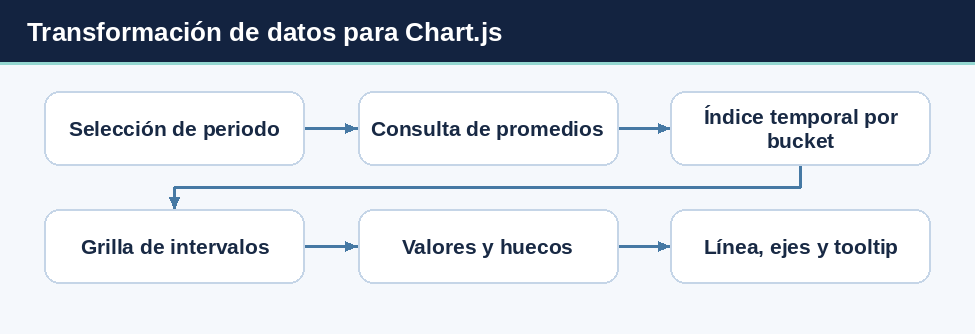

## Cómo leer los periodos

El periodo se cuenta hacia atrás desde el fin de la consulta. La API devuelve `start`, `end`,
`step_seconds` y `points`. Cada punto tiene un atributo `bucket` con el inicio del intervalo y los
promedios por indicador. El mismo conjunto de puntos incluye temperatura, humedad y gas.

| Botón | Parámetro | Ventana | Paso |
| --- | --- | --- | --- |
| Día | `day` | 24 horas hacia atrás | 15 minutos |
| Semana | `week` | 7 días hacia atrás | 4 horas |
| Mes | `month` | 30 días hacia atrás | 1 día |

Un promedio combina varias muestras del mismo intervalo. Si un intervalo de 15 minutos contiene dos
temperaturas válidas de 21 °C y 23 °C, su media es 22 °C. Un pico corto puede quedar suavizado al aumentar
el tamaño del intervalo. Usa la tabla para examinar las lecturas individuales.

Cambiar de métrica reutiliza `series.points` ya descargado. Cambiar de periodo o dispositivo inicia una nueva
consulta. La vista cancela la solicitud anterior con `AbortController` al cambiar esas dependencias o salir
de la vista general. `pending` limita el refresco a una petición activa por efecto. Reintentar incrementa una
variable que activa una nueva consulta.

[Efecto de consulta en Dashboard.svelte](../../frontend/src/GUI/views/Dashboard.svelte)

## Canvas, tiempo y ausencia de muestras

Un canvas es una superficie de píxeles que se dibuja mediante JavaScript. Svelte controla cuándo existe
el elemento. Chart.js obtiene su referencia con `bind:this` y dibuja líneas, rellenos y ejes. La limpieza
del efecto ejecuta `chart.destroy()` para liberar la instancia al reconstruir el gráfico. La barrera
`if (!canvas) return` espera a que el elemento exista en el DOM.

Las fechas ISO se convierten a milisegundos con `Date.parse`. El componente multiplica `step_seconds`
por 1000 y construye las posiciones `inicio + índice × paso`. Un `Map` asocia el inicio de cada
intervalo con el valor de la métrica. Para los intervalos ausentes o con esa métrica en `null`, el
componente guarda un punto con `y: null` y Chart.js presenta un corte en la línea. El número `0`
sigue siendo un valor válido.

```javascript
const values = new Map([[0, 22], [900_000, null], [1_800_000, 24]])
const points = Array.from({ length: 3 }, (_, index) => {
  const x = index * 900_000
  return { x, y: values.get(x) ?? null }
})
```

El eje X usa una escala lineal con marcas expresadas como hora o fecha de Ciudad de México.
El eje Y utiliza la unidad de la métrica activa. El tooltip muestra la hora inicial del intervalo y su
media. La línea se curva visualmente entre puntos consecutivos y cada punto sigue representando un
resultado agregado. En pantallas pequeñas se reducen las marcas horizontales.

[Adaptador gráfico SeriesChart.svelte](../../frontend/src/GUI/components/SeriesChart.svelte)

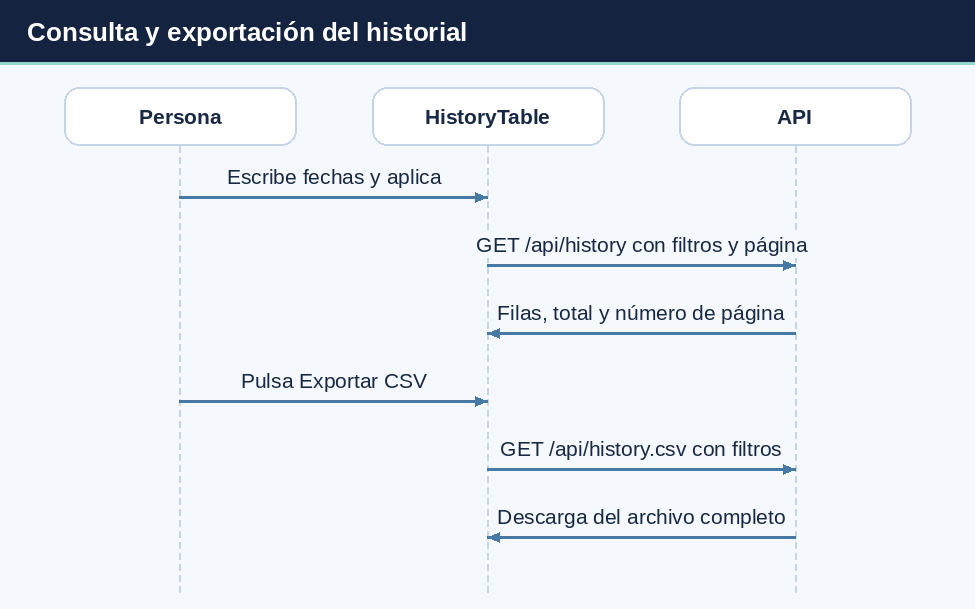

## Fechas, paginación y exportación

`draft` es el formulario editable y `filters` es el criterio aplicado. Esta separación permite completar
las fechas antes de consultar. Si Desde es posterior a Hasta, la vista muestra un error y deshabilita
**Aplicar filtros**. Al aplicar o limpiar filtros, se vuelve a la primera página. Cambiar de dispositivo
mantiene el rango aplicado y recalcula la página para el dispositivo nuevo. Cambiar de vista desmonta
`HistoryTable` y la siguiente visita empieza con un formulario nuevo.

Las fechas se transmiten como `YYYY-MM-DD` y la API interpreta los límites por días de Ciudad de México.
Hasta incluye ese día completo. Si una fila carece de `measured_at`, se utiliza `received_at` y se
presenta la etiqueta **Recepción**. El historial puede mostrar esas filas, mientras la tendencia
depende de marcas de medición para ubicar sus puntos.

La API recibe `page` y `per_page=20`. El frontend calcula las páginas disponibles al dividir `total`
por 20 y redondear hacia arriba. Ante un cambio de resultados y una página más allá del rango válido,
solicita la última página disponible. Cada consulta devuelve una vista de los datos en ese momento.
Si entran nuevas lecturas entre dos consultas, su posición en las páginas puede variar.

El enlace `download="monitor-aire.csv"` reutiliza el dispositivo y las fechas ya aplicadas. La consulta
de exportación va sin `page` ni `per_page`, así que el archivo incluye todas las filas que coinciden
con el filtro. La API construye el archivo. Las columnas y las fechas del CSV siguen su propio formato,
con fechas en UTC. Una hora del archivo puede verse distinta de la columna de la interfaz debido a la
zona horaria. La descarga queda desactivada si faltan resultados, si hay un error, mientras carga o
mientras las fechas en edición difieren del filtro aplicado.

- [Tabla y enlace de descarga](../../frontend/src/GUI/views/HistoryTable.svelte)
- [Construcción de parámetros con URLSearchParams](../../frontend/src/models/api.js)

## Práctica con datos disponibles

Selecciona una fecha con registros y aplica el filtro. Anota el total mostrado debajo de la tabla.
Ve a una página posterior si existe y descarga el CSV. Verifica que su conjunto de registros incluya
páginas anteriores. El total puede cambiar si el dispositivo envía nuevas lecturas entre la consulta
y la descarga. Compara una fila que diga Recepción con los campos `measured_at` y `received_at`
del archivo.

[Índice del frontend](README.md) · [Anterior · HTTP, sesión y tiempo real](02_http_sesion_y_tiempo_real.ipynb) · [Siguiente · Diagnóstico y pruebas](04_diagnostico_y_pruebas.ipynb)